<a href="https://colab.research.google.com/github/calvinarieri/machine-learning-course/blob/main/Week4_Exploring_Math_for_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 4: Statistical Analysis of Traffic Volume**
# **Objective**

This analysis uses the Metro Interstate Traffic Volume dataset to explore numerical traffic and weather variables. I will calculate descriptive statistics, examine the covariance and correlation between traffic volume and temperature, visualize their relationship, and present a simple mathematical model for predicting traffic volume.

The analysis supports my AI/ML-based intelligent traffic-light control project by exploring patterns in traffic demand and potential input features for traffic-volume prediction.

In [ ]:
import pandas as pd
# importing the data
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 48204
Number of columns: 9


In [ ]:
# Select numerical variables relevant to the project
variables = ["traffic_volume", "temp", "rain_1h", "clouds_all"]

data = df[variables].copy()

print("Selected variables:")
print(data.columns.tolist())

print("\nFirst five rows:")
display(data.head())

Selected variables:
['traffic_volume', 'temp', 'rain_1h', 'clouds_all']

First five rows:


,traffic_volume,temp,rain_1h,clouds_all
0,5545,288.28,0.0,40
1,4516,289.36,0.0,75
2,4767,289.58,0.0,90
3,5026,290.13,0.0,90
4,4918,291.14,0.0,75


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

statistics = pd.DataFrame({
    "Mean": data.mean(),
    "Median": data.median(),
    "Range": data.max() - data.min(),
    "Variance": data.var(ddof=1),
    "Standard Deviation": data.std(ddof=1)
})

print("Descriptive Statistics")
display(statistics.round(3))

Descriptive Statistics


,Mean,Median,Range,Variance,Standard Deviation
traffic_volume,3259.818,3380.00,7280.00,3947615.324,1986.861
temp,281.206,282.45,310.07,177.908,13.338
rain_1h,0.334,0.00,9831.30,2006.066,44.789
clouds_all,49.362,64.00,100.00,1522.229,39.016


In [ ]:
x_name = "temp"
y_name = "traffic_volume"

paired_data = data[[x_name, y_name]].dropna()

covariance = paired_data[x_name].cov(paired_data[y_name])
correlation = paired_data[x_name].corr(paired_data[y_name])

print(f"Covariance between {x_name} and {y_name}: {covariance:.3f}")
print(f"Pearson correlation: {correlation:.4f}")

Covariance between temp and traffic_volume: 3453.076
Pearson correlation: 0.1303


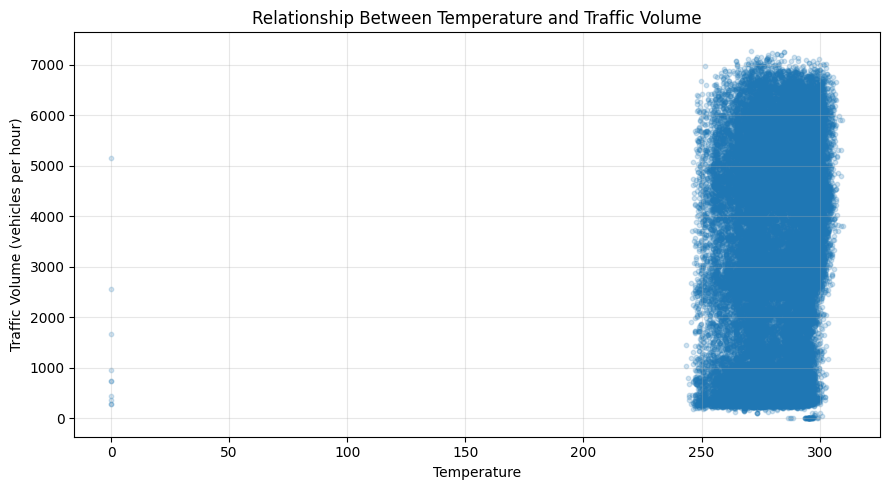

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    paired_data["temp"],
    paired_data["traffic_volume"],
    alpha=0.2,
    s=10
)

plt.xlabel("Temperature")
plt.ylabel("Traffic Volume (vehicles per hour)")
plt.title("Relationship Between Temperature and Traffic Volume")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **Interpretation of Statistical Results**
## **1. Descriptive Statistics**

The mean and median describe the central values of traffic volume, temperature, rainfall, and cloud coverage. The range represents the difference between the maximum and minimum values, while variance and standard deviation measure the spread of the observations.

For my AI/ML-based intelligent traffic-light control project, these statistics help me understand the distribution and variability of traffic and weather data. This information can guide the selection of relevant features for a machine-learning model designed to predict traffic volume.

## **2. Covariance and Correlation Analysis**

The covariance between temperature and traffic volume is 3453.076, while the Pearson correlation coefficient is 0.1303.

The positive covariance indicates that temperature and traffic volume tend to vary in the same direction. The correlation coefficient indicates a weak positive linear relationship between the two variables. This suggests that higher temperatures are associated with slightly higher traffic volumes in the dataset, although the relationship is not strong.

The scatter plot provides a visual representation of this relationship and helps illustrate how traffic volume varies at different temperatures. Temperature may be useful as an input feature for traffic-volume prediction, but its predictive value should be evaluated alongside other variables, such as time of day, day of the week, holidays, and weather conditions.

## **3. Correlation Does Not Imply Causation**

Correlation does not necessarily imply causation. Although temperature and traffic volume have a weak positive relationship, this does not establish that changes in temperature cause changes in traffic volume. Other factors, including commuting patterns, holidays, rainfall, and time-related patterns, may influence traffic demand.

Further analysis and model evaluation are necessary to determine how useful temperature is for predicting traffic volume. A machine-learning model that incorporates multiple relevant features may provide more informative predictions than one based on temperature alone.

## **Conclusion**

The statistical analysis provides an initial understanding of the traffic-volume dataset and its relationship with weather conditions. The weak positive correlation between temperature and traffic volume suggests that temperature alone may have limited explanatory value for their linear relationship. These findings support further investigation using multiple traffic, weather, and time-related features to develop a model for predicting traffic volume and supporting intelligent traffic-light control.

# Input → Function/Model → Output

For my AI/ML-based intelligent traffic-light control project, I will use **temperature** as the input variable and **traffic volume** as the output variable.

The relationship can be represented as follows:

$$
\underbrace{x = \text{Temperature}}_{\text{Input}}
\longrightarrow
\underbrace{f(x) = a + bx}_{\text{Linear Model}}
\longrightarrow
\underbrace{\hat{y} = \text{Predicted Traffic Volume}}_{\text{Output}}
$$

The mathematical expression is:

$$
\hat{y} = a + bx
$$

Where:

- $x$ represents the input variable (temperature).
- $a$ represents the intercept.
- $b$ represents the estimated coefficient of temperature.
- $\hat{y}$ represents the predicted traffic volume.
- $f(x)$ represents the linear prediction model.

This simple model illustrates how an input feature can be used to estimate traffic demand. In practice, a more effective traffic-prediction model should consider additional relevant variables, such as the hour of the day, day of the week, rainfall, cloud coverage, and holiday information. These features may help improve traffic-volume predictions and support intelligent traffic-light control decisions.
In Google Colab: Click + Text to create a Markdown cell, paste the code above, and run the cell to display the formatted equations and explanation.

In [8]:
# Fit a simple linear model: temperature -> traffic volume
slope, intercept = np.polyfit(
    paired_data["temp"],
    paired_data["traffic_volume"],
    1
)

print("Estimated linear model:")
print(f"Predicted traffic volume = {intercept:.2f} "
      f"+ ({slope:.2f} × temperature)")


Estimated linear model:
Predicted traffic volume = -2198.19 + (19.41 × temperature)
